1. **IMPORTING THE DEPENDENCIES**

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split , cross_val_score , RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix , classification_report , accuracy_score
from xgboost import XGBClassifier
import pickle

**2. DATA LOADING & UNDERSTANDING**

In [4]:
#READ THE CSV DATA TO A PANDAS DATAFRAME
df = pd.read_csv("/content/train (2).csv")

INITIAL INSPECTION

In [5]:
df.shape

(800, 22)

In [6]:
df.head()

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,...,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
0,1,1,0,1,0,1,0,1,0,1,...,f,?,no,no,Austria,no,6.351166,18 and more,Self,0
1,2,0,0,0,0,0,0,0,0,0,...,m,?,no,no,India,no,2.255185,18 and more,Self,0
2,3,1,1,1,1,1,1,1,1,1,...,m,White-European,no,yes,United States,no,14.851484,18 and more,Self,1
3,4,0,0,0,0,0,0,0,0,0,...,f,?,no,no,United States,no,2.276617,18 and more,Self,0
4,5,0,0,0,0,0,0,0,0,0,...,m,?,no,no,South Africa,no,-4.777286,18 and more,Self,0


In [7]:
df.tail()

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,...,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
795,796,0,1,0,0,0,0,0,0,1,...,m,Hispanic,no,no,New Zealand,no,12.999501,18 and more,Self,0
796,797,0,1,1,0,0,1,0,1,1,...,m,White-European,no,no,Cyprus,no,13.561518,18 and more,Self,0
797,798,0,0,0,0,0,0,0,0,0,...,m,South Asian,yes,no,New Zealand,no,2.653177,18 and more,Self,0
798,799,0,0,0,0,0,0,0,0,0,...,f,?,no,no,Canada,no,9.069342,18 and more,Self,0
799,800,0,1,0,0,0,0,0,0,0,...,f,?,no,no,United Arab Emirates,yes,2.243304,18 and more,Self,0


In [8]:
#display all columns of a dataframe
pd.set_option('display.max_columns', None)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               800 non-null    int64  
 1   A1_Score         800 non-null    int64  
 2   A2_Score         800 non-null    int64  
 3   A3_Score         800 non-null    int64  
 4   A4_Score         800 non-null    int64  
 5   A5_Score         800 non-null    int64  
 6   A6_Score         800 non-null    int64  
 7   A7_Score         800 non-null    int64  
 8   A8_Score         800 non-null    int64  
 9   A9_Score         800 non-null    int64  
 10  A10_Score        800 non-null    int64  
 11  age              800 non-null    float64
 12  gender           800 non-null    object 
 13  ethnicity        800 non-null    object 
 14  jaundice         800 non-null    object 
 15  austim           800 non-null    object 
 16  contry_of_res    800 non-null    object 
 17  used_app_before 

In [10]:
#convert age column to integer
df["age"] = df["age"].astype(int)

In [11]:
df.head(2)

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
0,1,1,0,1,0,1,0,1,0,1,1,38,f,?,no,no,Austria,no,6.351166,18 and more,Self,0
1,2,0,0,0,0,0,0,0,0,0,0,47,m,?,no,no,India,no,2.255185,18 and more,Self,0


In [12]:
for col in df.columns:
  numerical_features = ["ID" , "age" , "result"]
  if col not in numerical_features:
                        print(col,df[col].unique())
                        print("-"*50)

A1_Score [1 0]
--------------------------------------------------
A2_Score [0 1]
--------------------------------------------------
A3_Score [1 0]
--------------------------------------------------
A4_Score [0 1]
--------------------------------------------------
A5_Score [1 0]
--------------------------------------------------
A6_Score [0 1]
--------------------------------------------------
A7_Score [1 0]
--------------------------------------------------
A8_Score [0 1]
--------------------------------------------------
A9_Score [1 0]
--------------------------------------------------
A10_Score [1 0]
--------------------------------------------------
gender ['f' 'm']
--------------------------------------------------
ethnicity ['?' 'White-European' 'Middle Eastern ' 'Pasifika' 'Black' 'Others'
 'Hispanic' 'Asian' 'Turkish' 'South Asian' 'Latino' 'others']
--------------------------------------------------
jaundice ['no' 'yes']
--------------------------------------------------
austim

In [13]:
# dropping ID and age_desc column
df = df.drop(columns = ["ID" , "age_desc"])


In [14]:
df.shape

(800, 20)

In [15]:
df.head()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,relation,Class/ASD
0,1,0,1,0,1,0,1,0,1,1,38,f,?,no,no,Austria,no,6.351166,Self,0
1,0,0,0,0,0,0,0,0,0,0,47,m,?,no,no,India,no,2.255185,Self,0
2,1,1,1,1,1,1,1,1,1,1,7,m,White-European,no,yes,United States,no,14.851484,Self,1
3,0,0,0,0,0,0,0,0,0,0,23,f,?,no,no,United States,no,2.276617,Self,0
4,0,0,0,0,0,0,0,0,0,0,43,m,?,no,no,South Africa,no,-4.777286,Self,0


In [16]:
df.columns

Index(['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
       'result', 'relation', 'Class/ASD'],
      dtype='object')

In [17]:
df['contry_of_res'].unique()

array(['Austria', 'India', 'United States', 'South Africa', 'Jordan',
       'United Kingdom', 'Brazil', 'New Zealand', 'Canada', 'Kazakhstan',
       'United Arab Emirates', 'Australia', 'Ukraine', 'Iraq', 'France',
       'Malaysia', 'Viet Nam', 'Egypt', 'Netherlands', 'Afghanistan',
       'Oman', 'Italy', 'AmericanSamoa', 'Bahamas', 'Saudi Arabia',
       'Ireland', 'Aruba', 'Sri Lanka', 'Russia', 'Bolivia', 'Azerbaijan',
       'Armenia', 'Serbia', 'Ethiopia', 'Sweden', 'Iceland', 'Hong Kong',
       'Angola', 'China', 'Germany', 'Spain', 'Tonga', 'Pakistan', 'Iran',
       'Argentina', 'Japan', 'Mexico', 'Nicaragua', 'Sierra Leone',
       'Czech Republic', 'Niger', 'Romania', 'Cyprus', 'Belgium',
       'Burundi', 'Bangladesh'], dtype=object)

In [18]:
# define the mapping dictionary for country names

mapping = {
    "Viet Nam" : "Vietnam",
    "AmericanSamoa" : "United States",
    "Hong Kong" : "China"
}

#  replace the value in the counrty column

df["contry_of_res"] = df["contry_of_res"].replace(mapping)


In [19]:
df['contry_of_res'].unique()

array(['Austria', 'India', 'United States', 'South Africa', 'Jordan',
       'United Kingdom', 'Brazil', 'New Zealand', 'Canada', 'Kazakhstan',
       'United Arab Emirates', 'Australia', 'Ukraine', 'Iraq', 'France',
       'Malaysia', 'Vietnam', 'Egypt', 'Netherlands', 'Afghanistan',
       'Oman', 'Italy', 'Bahamas', 'Saudi Arabia', 'Ireland', 'Aruba',
       'Sri Lanka', 'Russia', 'Bolivia', 'Azerbaijan', 'Armenia',
       'Serbia', 'Ethiopia', 'Sweden', 'Iceland', 'China', 'Angola',
       'Germany', 'Spain', 'Tonga', 'Pakistan', 'Iran', 'Argentina',
       'Japan', 'Mexico', 'Nicaragua', 'Sierra Leone', 'Czech Republic',
       'Niger', 'Romania', 'Cyprus', 'Belgium', 'Burundi', 'Bangladesh'],
      dtype=object)

In [20]:
# target class distribution

df["Class/ASD"].value_counts()

,count
Class/ASD,
0,639
1,161


**INSIGHTS**

1. Missing values in ethinicity & relation
2. age_desc column has only 1 unique value . Hence it has been removed from the dataset as it is of no use
3. Fix the country names
4. There is a class imbalance in the target column


**EXPLORATORY DATA ANALYSIS (EDA)**

In [21]:
df.shape

(800, 20)

In [22]:
df.columns

Index(['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
       'result', 'relation', 'Class/ASD'],
      dtype='object')

In [23]:
df.head()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,relation,Class/ASD
0,1,0,1,0,1,0,1,0,1,1,38,f,?,no,no,Austria,no,6.351166,Self,0
1,0,0,0,0,0,0,0,0,0,0,47,m,?,no,no,India,no,2.255185,Self,0
2,1,1,1,1,1,1,1,1,1,1,7,m,White-European,no,yes,United States,no,14.851484,Self,1
3,0,0,0,0,0,0,0,0,0,0,23,f,?,no,no,United States,no,2.276617,Self,0
4,0,0,0,0,0,0,0,0,0,0,43,m,?,no,no,South Africa,no,-4.777286,Self,0


In [24]:
df.describe()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,result,Class/ASD
count,800.000000,800.000000,800.000000,800.00000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,0.560000,0.530000,0.450000,0.41500,0.395000,0.303750,0.397500,0.508750,0.495000,0.617500,27.963750,8.537303,0.201250
std,0.496697,0.499411,0.497805,0.49303,0.489157,0.460164,0.489687,0.500236,0.500288,0.486302,16.329827,4.807676,0.401185
min,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,-6.137748,0.000000
25%,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,17.000000,5.306575,0.000000
50%,1.000000,1.000000,0.000000,0.00000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,24.000000,9.605299,0.000000
75%,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,35.250000,12.514484,0.000000
max,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,89.000000,15.853126,1.000000


**Univariate Analysis**


Numerical Columns :



*   age
*   result



In [25]:
# set the desired theme
sns.set_theme(style="whitegrid")

Distribution Plots

Mean of Age: 27.96375
Median of Age: 24.0


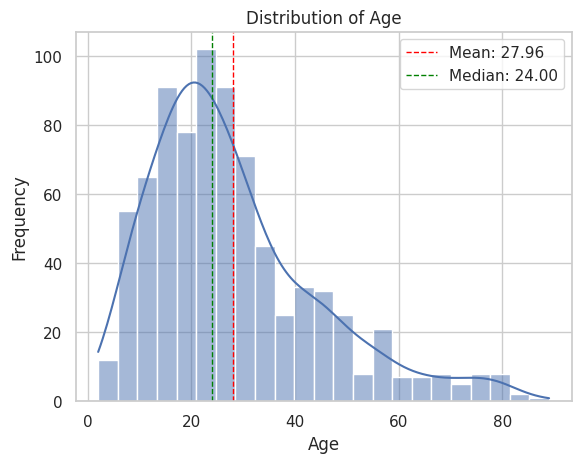

In [29]:
# Histogram for "age"

sns.histplot(df["age"], kde=True)
plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

#calulate mean and median
age_mean = df["age"].mean()
age_median = df["age"].median()

print("Mean of Age:", age_mean)
print("Median of Age:", age_median)

#add vertiCAL lines for mean and median
plt.axvline(age_mean, color='red', linestyle='dashed', linewidth=1, label=f'Mean: {age_mean:.2f}')
plt.axvline(age_median, color='green', linestyle='dashed', linewidth=1, label=f'Median: {age_median:.2f}')
plt.legend()

plt.show()

Mean of result: 8.537303106501248
Median of result: 9.605299308


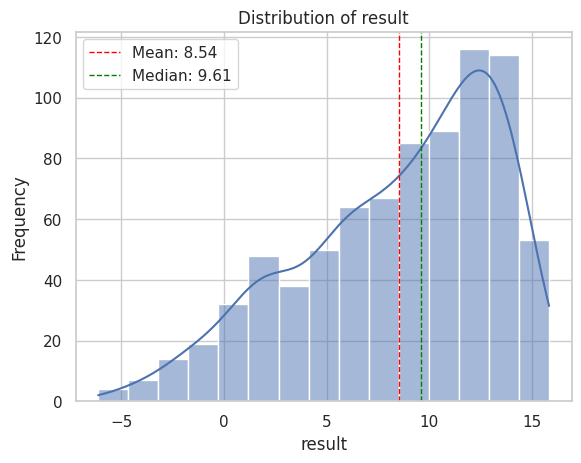

In [30]:
# Histogram for "result"

sns.histplot(df["result"], kde=True)
plt.title("Distribution of result")
plt.xlabel("result")
plt.ylabel("Frequency")

#calulate mean and median
result_mean = df["result"].mean()
result_median = df["result"].median()

print("Mean of result:", result_mean)
print("Median of result:", result_median)

#add vertical lines for mean and median
plt.axvline(result_mean, color='red', linestyle='dashed', linewidth=1, label=f'Mean: {result_mean:.2f}')
plt.axvline(result_median, color='green', linestyle='dashed', linewidth=1, label=f'Median: {result_median:.2f}')
plt.legend()

plt.show()

Box plots for identifying outliers in the  numerical columns

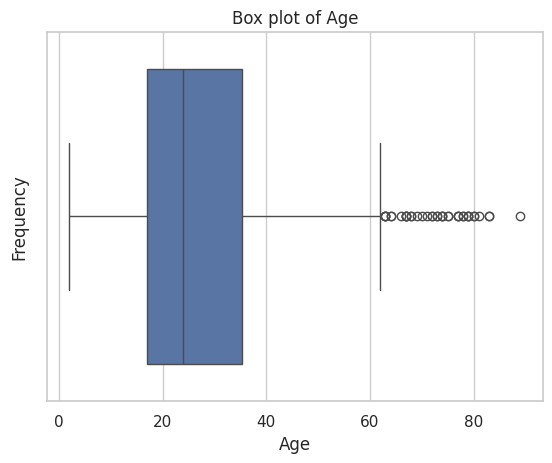

In [31]:
# box plots

sns.boxplot(x=df["age"])
plt.title("Box plot of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()


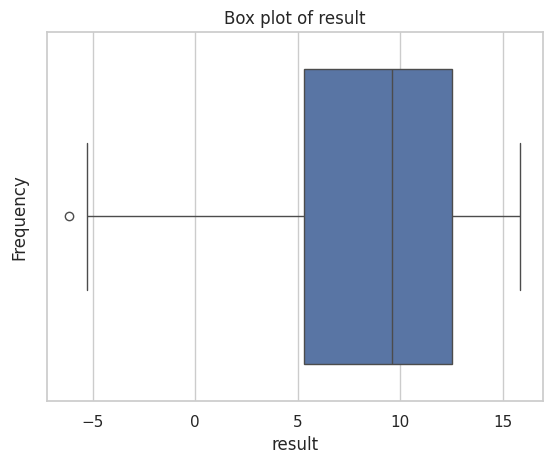

In [32]:
# box plots

sns.boxplot(x=df["result"])
plt.title("Box plot of result")
plt.xlabel("result")
plt.ylabel("Frequency")
plt.show()

In [33]:

# count the outliers using IQR method

Q1 = df["age"].quantile(0.25)
Q3 = df["age"].quantile(0.75)

IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

age_outliers = df[(df["age"] < lower_bound) | (df["age"] > upper_bound)]


In [34]:
len(age_outliers)

39

In [35]:

# count the outliers using IQR method

Q1 = df["result"].quantile(0.25)
Q3 = df["result"].quantile(0.75)

IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

result_outliers = df[(df["result"] < lower_bound) | (df["result"] > upper_bound)]


In [36]:
len(result_outliers)

1

Categorical Columns :

In [37]:
df.columns

Index(['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
       'result', 'relation', 'Class/ASD'],
      dtype='object')

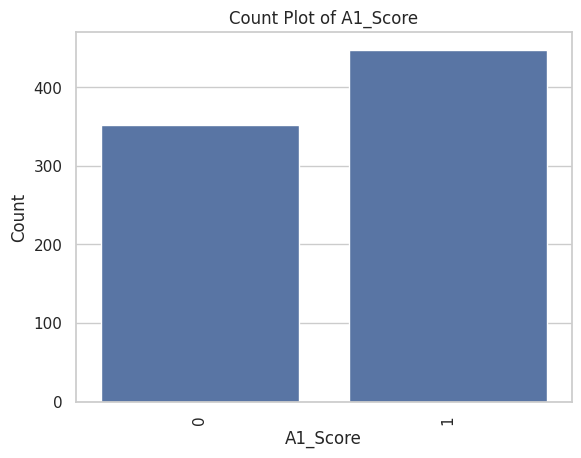

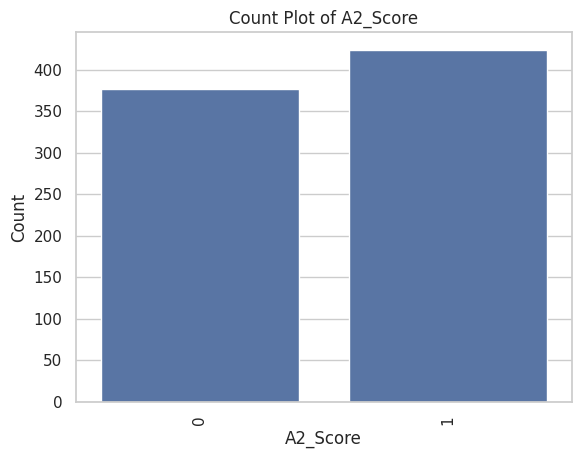

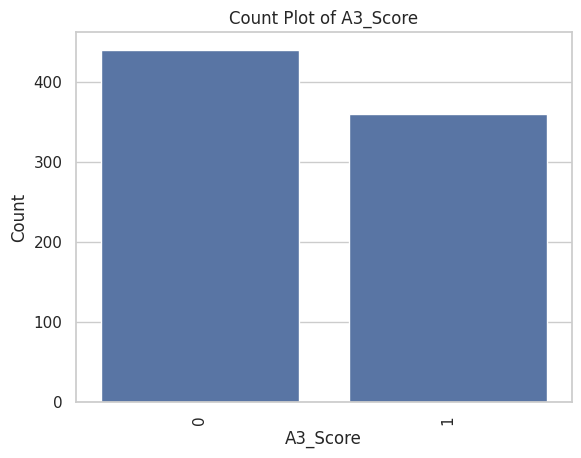

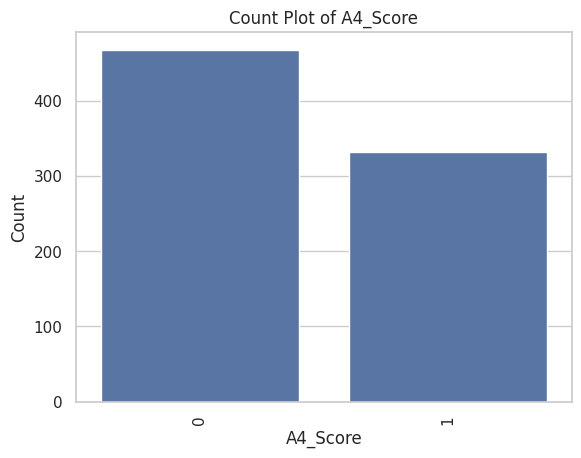

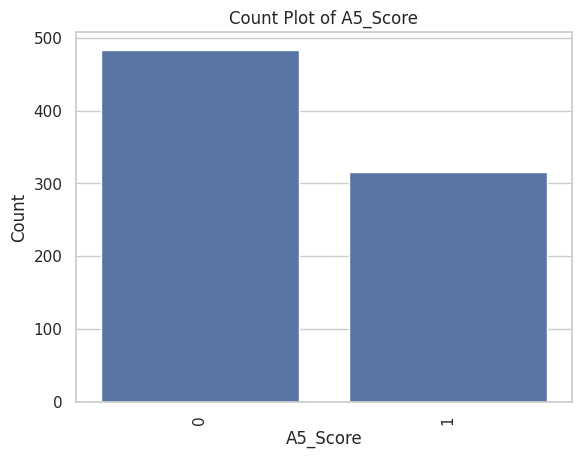

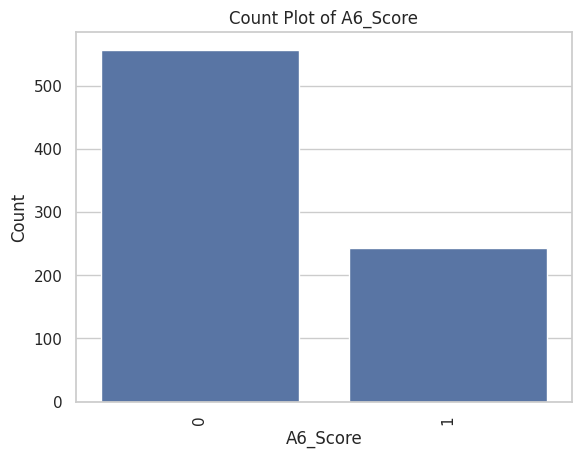

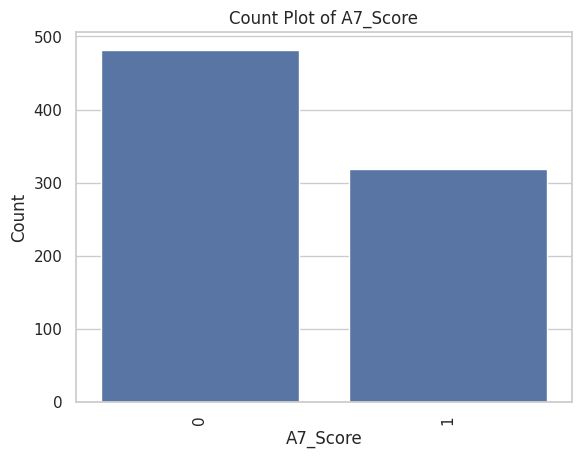

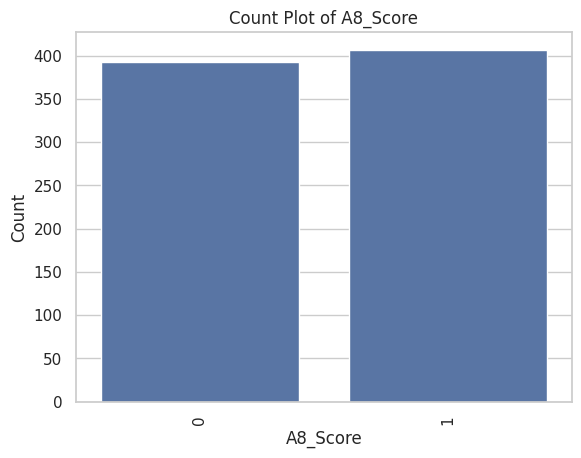

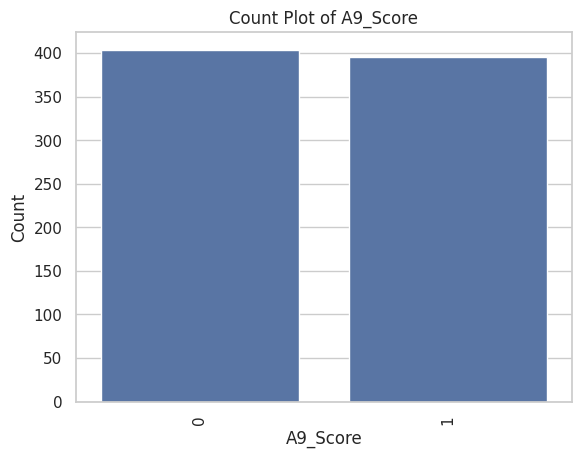

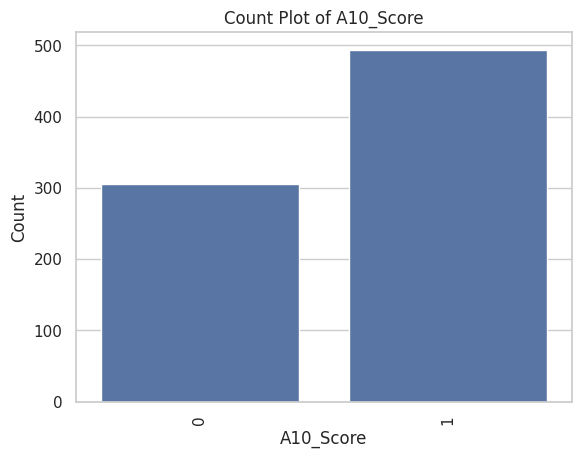

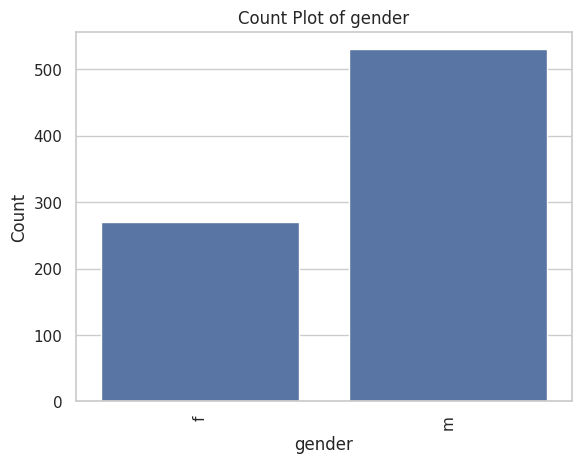

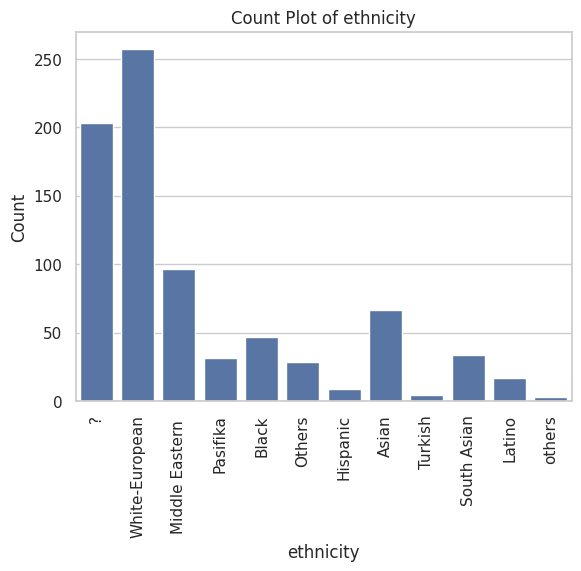

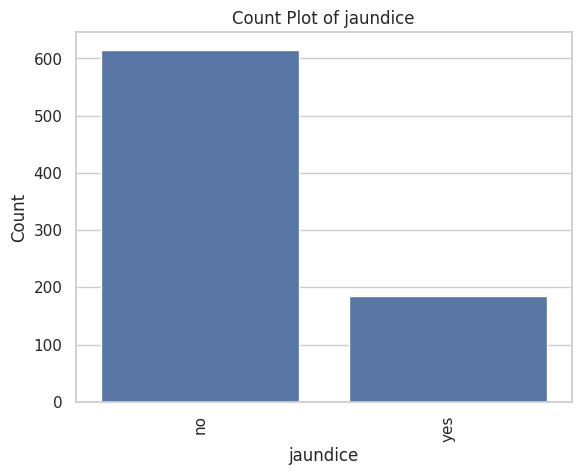

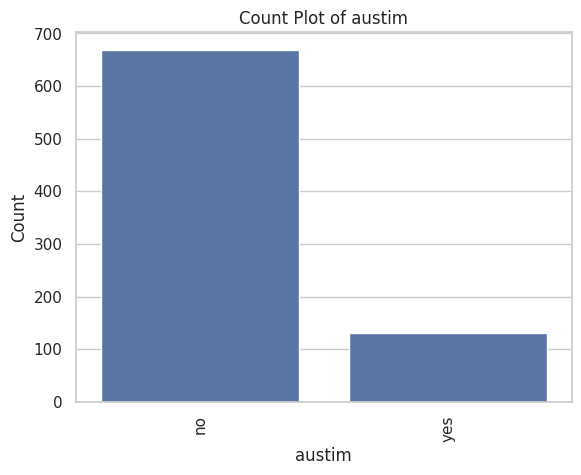

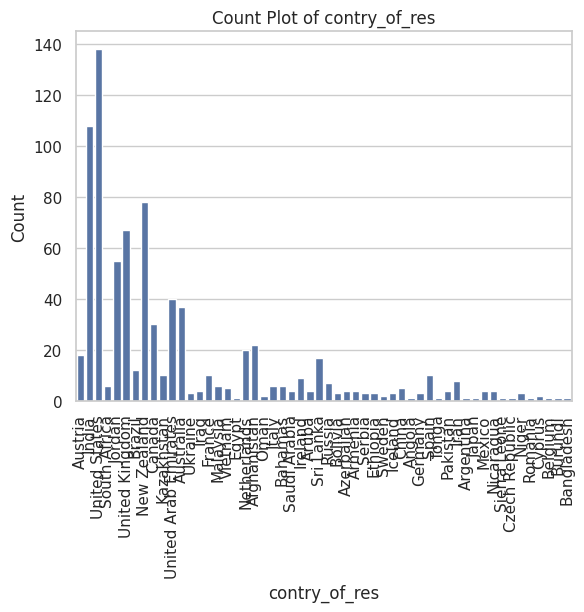

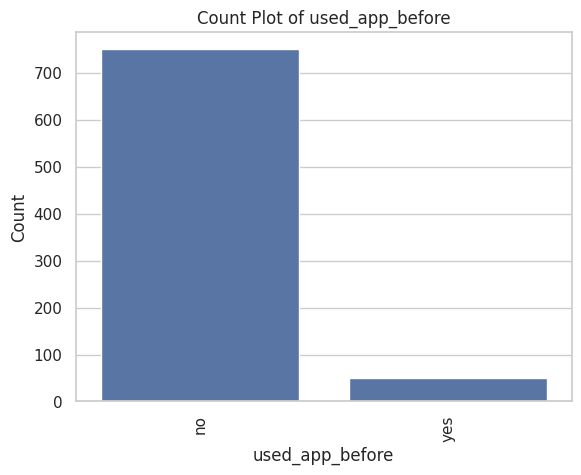

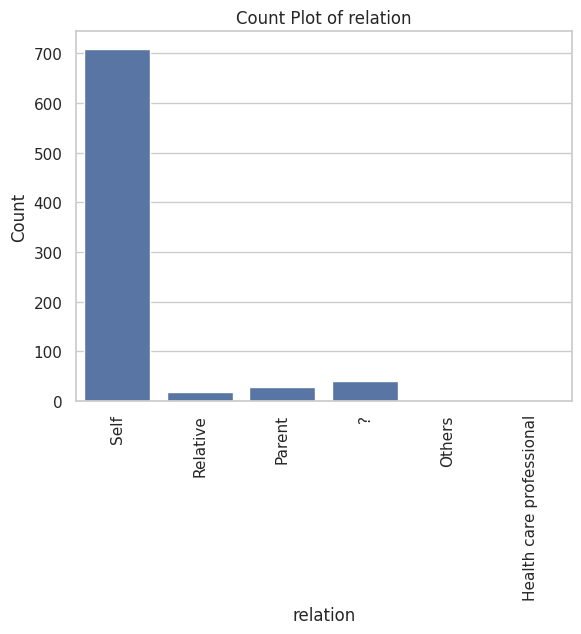

In [38]:
categorical_columns=['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score',  'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
        'relation', ]

for col in categorical_columns:
  sns.countplot(x=df[col])
  plt.title(f"Count Plot of {col}")
  plt.xlabel(col)
  plt.ylabel("Count")
  plt.xticks(rotation=90)
  plt.show()

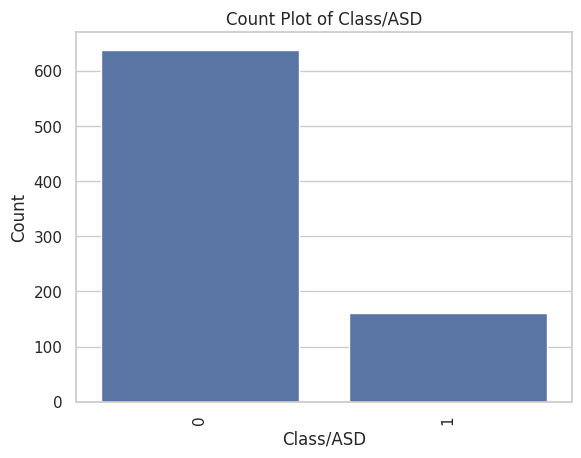

In [39]:
# countplot for the target column (Class/ASD)

sns.countplot(x=df["Class/ASD"])
plt.title("Count Plot of Class/ASD")
plt.xlabel("Class/ASD")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.show()

Handling missing values in ethinicity and relation for correlation heatmap


In [40]:
df["ethnicity"] = df["ethnicity"].replace({"?":"Others" , "others":"Others"})

In [41]:
df["relation"].unique()

array(['Self', 'Relative', 'Parent', '?', 'Others',
       'Health care professional'], dtype=object)

In [42]:
df["relation"] = df["relation"].replace({"?":"Others" , "Relative":"Others" , "Parent":"Others" , "Health care professional":"Others"})

**Label Encoding**

In [43]:
# identify columns with "object" datatype
object_columns = df.select_dtypes(include=["object"]).columns

In [44]:
print(object_columns)

Index(['gender', 'ethnicity', 'jaundice', 'austim', 'contry_of_res',
       'used_app_before', 'relation'],
      dtype='object')


In [45]:
# initialize a dictionary to store the encoders
encoders = {}

#apply label encoding and store the encoders
for column in object_columns :
  label_encoder = LabelEncoder()
  df[column] = label_encoder.fit_transform(df[column])
  encoders[column]= label_encoder  #saving the encoder for this column

# save the encoders as a pickle file
with open("encoders.pkl", "wb") as file:
  pickle.dump(encoders, file)

In [46]:
encoders

{'gender': LabelEncoder(),
 'ethnicity': LabelEncoder(),
 'jaundice': LabelEncoder(),
 'austim': LabelEncoder(),
 'contry_of_res': LabelEncoder(),
 'used_app_before': LabelEncoder(),
 'relation': LabelEncoder()}

In [47]:
df.head()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,relation,Class/ASD
0,1,0,1,0,1,0,1,0,1,1,38,0,5,0,0,6,0,6.351166,1,0
1,0,0,0,0,0,0,0,0,0,0,47,1,5,0,0,23,0,2.255185,1,0
2,1,1,1,1,1,1,1,1,1,1,7,1,9,0,1,52,0,14.851484,1,1
3,0,0,0,0,0,0,0,0,0,0,23,0,5,0,0,52,0,2.276617,1,0
4,0,0,0,0,0,0,0,0,0,0,43,1,5,0,0,44,0,-4.777286,1,0


**Bivariate Analysis**

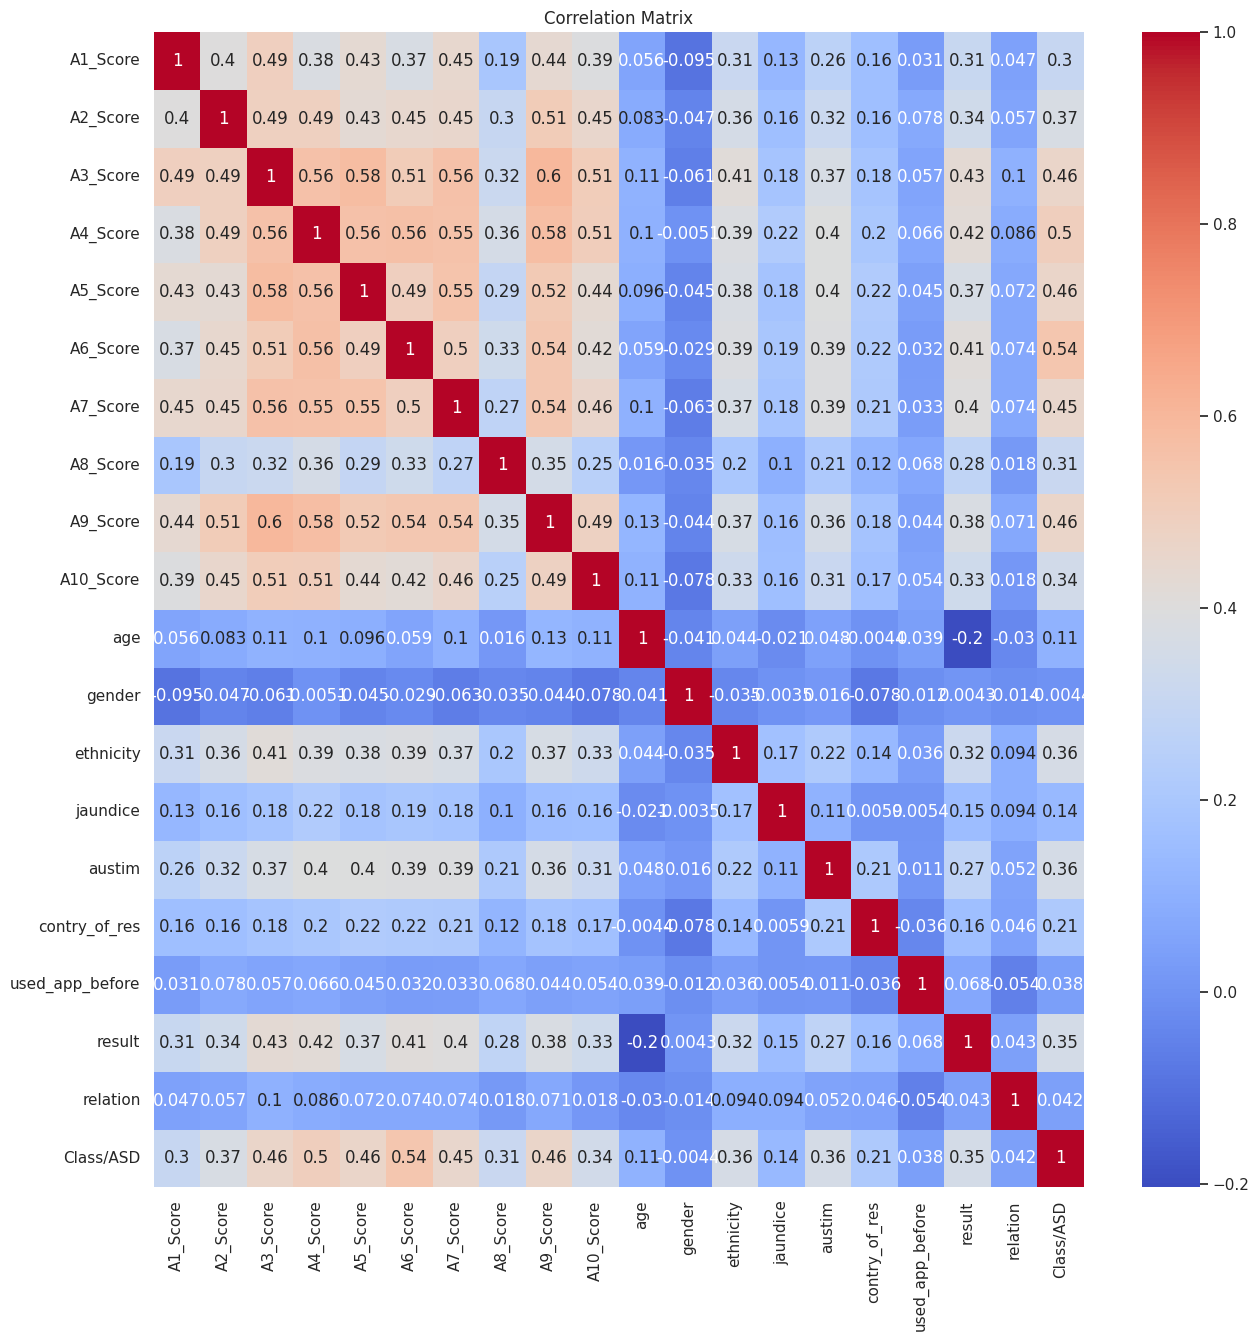

In [50]:
# correlation matrix
plt.figure(figsize=(15,15))
sns.heatmap(df.corr(),annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

**Insights from EDA**
1. There are few outliers in the numerical columns ( age , results)

2. There is a class imbalance in the target column

3. There is a class imbalance in the categorical features

4. We don't have any highly correlated column

5. performed label encoding and saved the encoders

**DATA PREPROCESSING**

HANDLING OUTLIERS

In [51]:
#function to replace the outliers with median

def replace_outliers_with_median(df,column):

  Q1 = df[column].quantile(0.25)
  Q3 = df[column].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  median = df[column].median()

  # replace outliers with median value

  df[column] = df[column].apply(lambda x : median if (x < lower_bound) or (x > upper_bound) else x)

  return df

In [52]:

# replace the outliers in the age column

df = replace_outliers_with_median(df,"age")

#replace the outliers in the result column

df = replace_outliers_with_median(df,"result")


**train test split**

In [53]:
X = df.drop(columns = ["Class/ASD"])
y = df["Class/ASD"]

In [54]:
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.2,random_state=42)

**SMOTE ( SYNTHETIC MINORITY OVERSAMPLING TECHNIQUE ) **

In [55]:
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)


In [57]:
print(y_train_resampled.shape)

(1030,)


In [59]:
print(y_train_resampled.value_counts())

Class/ASD
1    515
0    515
Name: count, dtype: int64


**MODEL TRAIING**

In [60]:
# LIST OF CLASSIFIERS

model = {
    "DecisionTreeClassifier" : DecisionTreeClassifier(random_state=42),
    "RandomForestClassifier" : RandomForestClassifier(random_state=42),
    "XGBClassifier" : XGBClassifier(random_state=42)
}





In [61]:
# dictionary to store the cross validation results

cv_scores = {}

# perform 5-fold cross validation for each model

for model_name , model in model.items():
  print(f"Training {model_name} with default parameters... ")
  scores = cross_val_score(model,X_train_resampled,y_train_resampled,cv=5,scoring="accuracy")
  cv_scores[model_name] = scores
  print(f"{model_name} Cross-Validation accuracy : {np.mean(scores):.2f}")
  print("-"*50)

Training DecisionTreeClassifier with default parameters... 
DecisionTreeClassifier Cross-Validation accuracy : 0.86
--------------------------------------------------
Training RandomForestClassifier with default parameters... 
RandomForestClassifier Cross-Validation accuracy : 0.92
--------------------------------------------------
Training XGBClassifier with default parameters... 
XGBClassifier Cross-Validation accuracy : 0.90
--------------------------------------------------


In [62]:
cv_scores

{'DecisionTreeClassifier': array([0.7961165 , 0.87864078, 0.87378641, 0.8592233 , 0.87378641]),
 'RandomForestClassifier': array([0.90776699, 0.92718447, 0.9223301 , 0.91747573, 0.9223301 ]),
 'XGBClassifier': array([0.86893204, 0.9223301 , 0.90776699, 0.90776699, 0.91262136])}

**MODEL SELECTION AND HYPERPARAMETER TUNING **

In [64]:
#initializing modela

decision_tree_model = DecisionTreeClassifier(random_state=42)
random_forest_model = RandomForestClassifier(random_state=42)
xgb_model = XGBClassifier(random_state=42)


In [65]:
#Hyperparameter grids for  RandomizedSearchCV

param_grid_dt = {
    "criterion" : ["gini" , "entropy"],
    "max_depth" : [None , 10 , 20 , 30 , 50 , 70 ],
    "min_samples_split" : [2 , 5 , 10],
    "min_samples_leaf" : [1 , 2 , 4]
}

param_grid_rf = {
    "n_estimators" : [50,100,200,500],
    "max_depth" : [None , 10 , 20 , 30],
    "min_samples_split" : [2 , 5 , 10],
    "min_samples_leaf" : [1 , 2 , 4],
    "bootstrap" : [True , False]
}

param_grid_xgb = {
    "learning_rate" : [0.01 , 0.1 , 0.2 , 0.3],
    "n_estimators" : [50 , 100 , 200 , 500 ] ,
    "max_depth" : [3 , 5 , 7 , 10],
    "subsample" : [0.5 , 0.7 , 1.0],
    "colsample_bytree" : [0.5 , 0.7 , 1.0]

}



In [66]:
# hyperparameter tuning for 3 tree based models

# the below steps can be autometed by using a for loop or by using a pipeline

#perform RandomizedSeacrhCV for each model

random_search_dt = RandomizedSearchCV(estimator=decision_tree_model,param_distributions=param_grid_dt,n_iter=10,cv=5,scoring="accuracy",random_state=42)


random_search_rf = RandomizedSearchCV(estimator=random_forest_model,param_distributions=param_grid_rf,n_iter=10,cv=5,scoring="accuracy",random_state=42)


random_search_xgb = RandomizedSearchCV(estimator=xgb_model,param_distributions=param_grid_xgb, n_iter=10,cv=5,scoring="accuracy",random_state=42)





In [67]:
random_search_dt.fit(X_train_resampled,y_train_resampled)
random_search_rf.fit(X_train_resampled,y_train_resampled)
random_search_xgb.fit(X_train_resampled,y_train_resampled)

RandomizedSearchCV(cv=5,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=True,
                                           eval_metric=None, feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_constraint...
                                           max_leaves=None,
                                           min_child_weight=None, missing=nan,
                                           monotone_constraints=None,
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   param_distributions={'colsample_bytree': [0.5, 0.7, 1.0],
                                        'learning_rate': [0.01, 0.1, 0.2, 0.3],
                                        'max_depth': [3, 5, 7, 10],
                                        'n_estimators': [50, 100, 200, 500],
                                        'subsample': [0.5, 0.7, 1.0]},
                   random_state=42, scoring='accuracy')

In [68]:
#get the model with the best score

best_model = None
best_score = 0

if random_search_dt.best_score_ > best_score:
  best_score = random_search_dt.best_score_
  best_model = random_search_dt.best_estimator_

if random_search_rf.best_score_ > best_score:
  best_score = random_search_rf.best_score_
  best_model = random_search_rf.best_estimator_

if random_search_xgb.best_score_ > best_score:
  best_score = random_search_xgb.best_score_
  best_model = random_search_xgb.best_estimator_



In [71]:
print(f"Best Model: {best_model}")
print(f"Best Score: {best_score}")


Best Model: RandomForestClassifier(bootstrap=False, max_depth=10, random_state=42)
Best Score: 0.9223300970873787


In [72]:
#save the best model

with open("best_model.pkl","wb") as file:
  pickle.dump(best_model,file)

**EVALUATION**

In [74]:
# evaluate on the  test data
y_test_pred = best_model.predict(X_test)
test_accuracy = accuracy_score(y_test,y_test_pred)
print(f"Test Accuracy : {test_accuracy}")
print("Confusion Matrix :")
print(confusion_matrix(y_test,y_test_pred))
print("Classification Report :")
print(classification_report(y_test,y_test_pred))


Test Accuracy : 0.8375
Confusion Matrix :
[[109  15]
 [ 11  25]]
Classification Report :
              precision    recall  f1-score   support

           0       0.91      0.88      0.89       124
           1       0.62      0.69      0.66        36

    accuracy                           0.84       160
   macro avg       0.77      0.79      0.78       160
weighted avg       0.84      0.84      0.84       160



TO DO :

1. Build a predictive system with encoders and model file

2. See if you could improve the performance